# UAV Time Series Descriptive Mining Analysis

## Overview
This notebook performs comprehensive descriptive mining on UAV flight time series data to uncover patterns, anomalies, and hidden insights.

## Data Description
The dataset contains UAV flight data with the following columns:
- **bag**: Bag file identifier
- **timestamp_ns**: Nanosecond timestamp
- **Control Commands**: airspeed_cmd, roll_cmd, pitch_cmd, yaw_cmd
- **Measurements**: airspeed_meas, roll_meas, pitch_meas, yaw_meas
- **Errors**: airspeed_error, roll_error, pitch_error, yaw_error
- **Velocity**: vel_x, vel_y, vel_z
- **IMU**: imu_x, imu_y, imu_z
- **Fault Flags**: engine_fault, aileron_fault, elevator_fault, rudder_fault
- **dataset**: Data split identifier


In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from scipy import stats
import warnings
from mlxtend.frequent_patterns import apriori, association_rules,fpgrowth
from pyvis.network import Network
warnings.filterwarnings('ignore')

# Set visualization style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
%matplotlib inline

In [2]:
# Load the data
print("Loading UAV time series data...")
df = pd.read_csv('../descriptive/uav_timeseries.csv')
print(f"Dataset shape: {df.shape}")
print(f"Number of columns: {len(df.columns)}")
print("\nFirst few rows:")
df.head()

Loading UAV time series data...
Dataset shape: (180812, 25)
Number of columns: 25

First few rows:


,bag,timestamp_ns,airspeed_cmd,airspeed_meas,airspeed_error,roll_cmd,roll_meas,roll_error,pitch_cmd,pitch_meas,...,vel_y,vel_z,imu_x,imu_y,imu_z,engine_fault,aileron_fault,elevator_fault,rudder_fault,dataset
0,carbonZ_2018-07-18-12-10-11.bag,1531930511391720552,15.0,0.0,15.0,0.100000,2.954323,-2.854323,-2.55,8.487809,...,-0.312905,4.295179,-0.0748,-0.023208,-0.996428,0,0,0,0,test
1,carbonZ_2018-07-18-12-10-11.bag,1531930511452938696,15.0,0.0,15.0,30.340000,2.954323,27.385678,-1.31,8.487809,...,-0.312905,4.295179,-0.0748,-0.023208,-0.996428,0,0,0,0,test
2,carbonZ_2018-07-18-12-10-11.bag,1531930511484229416,15.0,0.0,15.0,30.320000,2.954323,27.365677,-1.31,8.487809,...,-0.312905,4.295179,-0.0748,-0.023208,-0.996428,0,0,0,0,test
3,carbonZ_2018-07-18-12-10-11.bag,1531930511543160328,15.0,0.0,15.0,30.299999,2.954323,27.345677,-1.31,8.487809,...,-0.279165,4.326915,-0.0748,-0.023208,-0.996428,0,0,0,0,test
4,carbonZ_2018-07-18-12-10-11.bag,1531930511568218792,15.0,0.0,15.0,31.920000,2.954323,28.965677,-5.60,8.487809,...,-0.279165,4.326915,-0.0748,-0.023208,-0.996428,0,0,0,0,test


In [3]:
# Define target columns from schema
fault_cols = ['engine_fault', 'aileron_fault', 'elevator_fault', 'rudder_fault']
error_cols = ['airspeed_error', 'roll_error', 'pitch_error', 'yaw_error']

# Print summary of faults present
print("Fault event counts:")
print(df[fault_cols].sum())

Fault event counts:
engine_fault      18270
aileron_fault     11856
elevator_fault      453
rudder_fault       2693
dtype: int64


In [4]:
df_binary = pd.DataFrame()

# Extract boolean flags for hardware faults
for col in fault_cols:
    if col in df.columns:
        df_binary[col] = (df[col] == 1).astype(bool)

# Flag top 5% highest error values (0.95 quantile ensures non-zero positive triggers)
for col in error_cols:
    if col in df.columns:
        threshold = df[col].abs().quantile(0.95)
        df_binary[f'high_{col}'] = (df[col].abs() > threshold).astype(bool)

print("Binary event totals:")
print(df_binary.sum())
# Lower support to 0.001 (0.1% threshold) to capture rare flight faults
frequent_itemsets = apriori(df_binary, min_support=0.001, use_colnames=True)

print(f"Total frequent itemsets found: {len(frequent_itemsets)}")
print(frequent_itemsets.head(10))

Binary event totals:
engine_fault           18270
aileron_fault           3043
elevator_fault           453
rudder_fault             523
high_airspeed_error        0
high_roll_error         9039
high_pitch_error        9039
high_yaw_error          9035
dtype: int64
Total frequent itemsets found: 15
    support                                     itemsets
0  0.101044                    frozenset({engine_fault})
1  0.016830                   frozenset({aileron_fault})
2  0.002505                  frozenset({elevator_fault})
3  0.002893                    frozenset({rudder_fault})
4  0.049991                 frozenset({high_roll_error})
5  0.049991                frozenset({high_pitch_error})
6  0.049969                  frozenset({high_yaw_error})
7  0.021155   frozenset({high_roll_error, engine_fault})
8  0.012848  frozenset({high_pitch_error, engine_fault})
9  0.006675    frozenset({high_yaw_error, engine_fault})


In [5]:
from mlxtend.frequent_patterns import association_rules

if not frequent_itemsets.empty:
    # Set lower confidence threshold to ensure rules are generated
    rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.1)
    rules = rules.sort_values(by="lift", ascending=False).reset_index(drop=True)
    
    print(f"Total rules mined: {len(rules)}")
    print(rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(10))
else:
    rules = pd.DataFrame()
    print("No frequent itemsets found. Try lowering min_support further.")

Total rules mined: 10
                                     antecedents  \
0                    frozenset({elevator_fault})   
1  frozenset({high_pitch_error, high_yaw_error})   
2      frozenset({high_yaw_error, engine_fault})   
3                   frozenset({high_roll_error})   
4                      frozenset({engine_fault})   
5                  frozenset({high_pitch_error})   
6                      frozenset({engine_fault})   
7                     frozenset({aileron_fault})   
8    frozenset({high_pitch_error, engine_fault})   
9                    frozenset({high_yaw_error})   

                     consequents   support  confidence       lift  
0  frozenset({high_pitch_error})  0.001620    0.646799  12.938272  
1      frozenset({engine_fault})  0.001471    0.791667   7.834857  
2  frozenset({high_pitch_error})  0.001471    0.220381   4.408402  
3      frozenset({engine_fault})  0.021155    0.423166   4.187933  
4   frozenset({high_roll_error})  0.021155    0.209360   4.187933

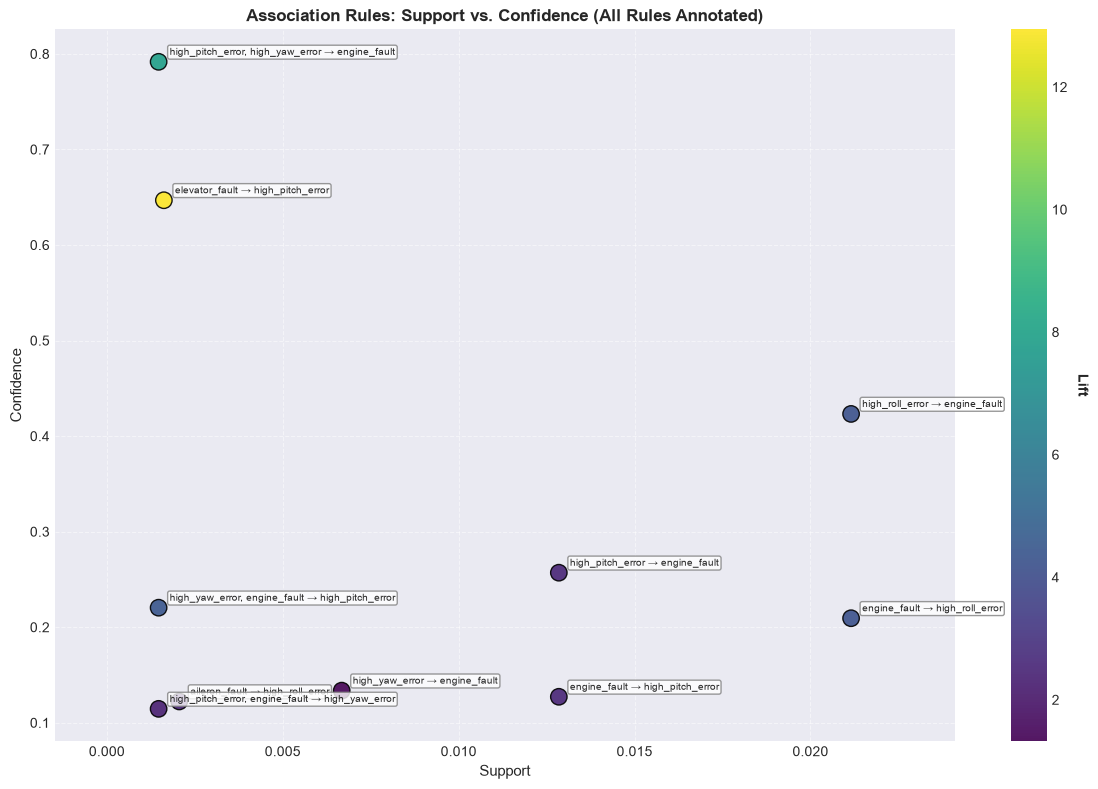

In [6]:
if not rules.empty:
    plt.figure(figsize=(12, 8))
    scatter = plt.scatter(
        rules['support'], rules['confidence'], 
        c=rules['lift'], cmap='viridis', s=140, alpha=0.9, edgecolors='black'
    )
    cbar = plt.colorbar(scatter)
    cbar.set_label('Lift', rotation=270, labelpad=15, fontweight='bold')
    
    # Annotate every single rule in the dataset
    for idx, row in rules.iterrows():
        ant = ", ".join(list(row['antecedents']))
        con = ", ".join(list(row['consequents']))
        label = f"{ant} → {con}"
        
        plt.annotate(
            label,
            (row['support'], row['confidence']),
            xytext=(8, 5), 
            textcoords='offset points',
            fontsize=7.5,
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="gray", alpha=0.8)
        )

    plt.xlabel('Support', fontsize=11)
    plt.ylabel('Confidence', fontsize=11)
    plt.title('Association Rules: Support vs. Confidence (All Rules Annotated)', fontsize=12, fontweight='bold')
    
    # Expand axes limits slightly to keep edge annotations inside the frame
    x_margin = (rules['support'].max() - rules['support'].min()) * 0.15 or 0.005
    plt.xlim(rules['support'].min() - x_margin, rules['support'].max() + x_margin)
    
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
else:
    print("Cannot render plot: rules DataFrame is empty.")

In [7]:
df_temporal = pd.DataFrame()

fault_cols = ['engine_fault', 'aileron_fault', 'elevator_fault', 'rudder_fault']
error_cols = ['airspeed_error', 'roll_error', 'pitch_error', 'yaw_error']

for col in fault_cols:
    if col in df.columns:
        df_temporal[col] = (df[col] == 1).astype(bool)

for col in error_cols:
    if col in df.columns:
        threshold = df[col].abs().quantile(0.95)
        df_temporal[f'high_{col}'] = (df[col].abs() > threshold).astype(bool)

# 2. Apply a 10-frame time lag to capture true downstream errors
lag_steps = 100
for col in ['high_airspeed_error', 'high_pitch_error', 'high_roll_error', 'high_yaw_error']:
    df_temporal[f'{col}_lag{lag_steps}'] = df_temporal[col].shift(-lag_steps).fillna(False)

# 3. Mine frequent itemsets using FP-Growth
frequent_itemsets = fpgrowth(df_temporal, min_support=0.001, use_colnames=True)

# 4. Generate association rules
raw_rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.1)

# 5. Filter function to remove tautological self-associations
def filter_temporal_tautologies(df_rules):
    valid_rows = []
    for idx, row in df_rules.iterrows():
        ant = set(row['antecedents'])
        con = set(row['consequents'])
        
        # Strip lag suffix to isolate root metric names
        ant_bases = {x.replace(f'_lag{lag_steps}', '') for x in ant}
        con_bases = {x.replace(f'_lag{lag_steps}', '') for x in con}
        
        # Keep rule only if antecedent and consequent cover distinct base metrics
        if not ant_bases.intersection(con_bases):
            valid_rows.append(row)
            
    return pd.DataFrame(valid_rows)

# Filter rules and sort by Lift
rules_fp_clean = filter_temporal_tautologies(raw_rules)

if not rules_fp_clean.empty:
    rules_fp_clean = rules_fp_clean.sort_values(by="lift", ascending=False).reset_index(drop=True)
    print(f"Discovered {len(rules_fp_clean)} non-tautological temporal rules:\n")
    print(rules_fp_clean[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(10))
else:
    print("No non-tautological rules found. Consider lowering min_support or trying lag_steps=5.")

Discovered 26 non-tautological temporal rules:

                                         antecedents  \
0                        frozenset({elevator_fault})   
1                        frozenset({elevator_fault})   
2                          frozenset({engine_fault})   
3  frozenset({high_roll_error_lag100, high_roll_e...   
4      frozenset({high_pitch_error, high_yaw_error})   
5          frozenset({high_yaw_error, engine_fault})   
6                          frozenset({rudder_fault})   
7  frozenset({high_yaw_error, high_pitch_error_la...   
8  frozenset({high_roll_error_lag100, high_pitch_...   
9          frozenset({high_yaw_error, engine_fault})   

                                         consequents   support  confidence  \
0                      frozenset({high_pitch_error})  0.001620    0.646799   
1               frozenset({high_pitch_error_lag100})  0.001106    0.441501   
2  frozenset({high_roll_error_lag100, high_roll_e...  0.014407    0.142583   
3                      

In [8]:
# Generate an interactive directed graph of Cause (Antecedent) -> Effect (Consequent)
net = Network(height="600px", width="100%", directed=True, notebook=True, cdn_resources='in_line')

# Add top rules as directed edges
top_rules = rules.head(20)

for idx, row in top_rules.iterrows():
    ant = ", ".join(list(row['antecedents']))
    con = ", ".join(list(row['consequents']))
    lift = round(row['lift'], 2)
    conf = round(row['confidence'], 2)
    
    # Add nodes
    net.add_node(ant, label=ant, color="#1f77b4", size=20)
    net.add_node(con, label=con, color="#ff7f0e", size=20)
    
    # Edge width reflects Lift, title displays metrics on hover
    net.add_edge(
        ant, con, 
        title=f"Lift: {lift} | Confidence: {conf}", 
        value=lift, 
        color="#2ca02c"
    )

# Replace net.show("association_rules_network.html") with this:
html_content = net.generate_html()

with open("association_rules_network.html", "w", encoding="utf-8") as f:
    f.write(html_content)

print("Saved interactive network graph to association_rules_network.html with UTF-8 encoding.")

Saved interactive network graph to association_rules_network.html with UTF-8 encoding.


In [9]:
# 1. Build a clean separation of instantaneous faults (t=0) and lagged errors (t+10, t+20)
df_clean_cascade = pd.DataFrame()

# Antecedent Candidates: Pure Hardware Faults at t=0
fault_cols = ['engine_fault', 'aileron_fault', 'elevator_fault', 'rudder_fault']
for col in fault_cols:
    if col in df.columns:
        df_clean_cascade[col] = (df[col] == 1).astype(bool)

# Consequent Candidates: Lagged Errors ONLY (t+10, t+20)
error_cols = ['airspeed_error', 'roll_error', 'pitch_error', 'yaw_error']
for col in error_cols:
    if col in df.columns:
        threshold = df[col].abs().quantile(0.95)
        high_err = (df[col].abs() > threshold)
        
        df_clean_cascade[f'high_{col}_lag10'] = high_err.shift(-10).fillna(False)
        df_clean_cascade[f'high_{col}_lag20'] = high_err.shift(-20).fillna(False)

# 2. Mine frequent itemsets with low support to catch brief surface faults
frequent_itemsets = fpgrowth(df_clean_cascade, min_support=0.00005, use_colnames=True)
raw_rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.1)

# 3. STRICT FILTERING:
# - Antecedent MUST contain ONLY fault items (no _lag columns allowed)
# - Consequent MUST contain ONLY lagged error items (no fault columns allowed)
def is_pure_root_cause_rule(row):
    ant = set(row['antecedents'])
    con = set(row['consequents'])
    
    ant_has_only_faults = all('fault' in item and 'lag' not in item for item in ant)
    con_has_only_lagged_errors = all('lag' in item and 'fault' not in item for item in con)
    
    return ant_has_only_faults and con_has_only_lagged_errors

pure_rules = raw_rules[raw_rules.apply(is_pure_root_cause_rule, axis=1)].copy()
pure_rules = pure_rules.sort_values(by="lift", ascending=False).reset_index(drop=True)

# Format strings for visualization
pure_rules['antecedent_str'] = pure_rules['antecedents'].apply(lambda x: ", ".join(list(x)))
pure_rules['consequent_str'] = pure_rules['consequents'].apply(lambda x: ", ".join(list(x)))

print(f"Isolated {len(pure_rules)} STRICT root-cause rules:\n")
print(pure_rules[['antecedent_str', 'consequent_str', 'support', 'confidence', 'lift']].head(10))

Isolated 64 STRICT root-cause rules:

   antecedent_str                                     consequent_str  \
0  elevator_fault     high_pitch_error_lag10, high_pitch_error_lag20   
1  elevator_fault                             high_pitch_error_lag20   
2  elevator_fault                             high_pitch_error_lag10   
3    engine_fault  high_pitch_error_lag10, high_roll_error_lag10,...   
4    engine_fault  high_yaw_error_lag10, high_roll_error_lag20, h...   
5    engine_fault  high_pitch_error_lag10, high_yaw_error_lag20, ...   
6    engine_fault  high_pitch_error_lag10, high_roll_error_lag20,...   
7    engine_fault  high_roll_error_lag20, high_yaw_error_lag20, h...   
8    engine_fault  high_pitch_error_lag10, high_roll_error_lag20,...   
9    engine_fault  high_pitch_error_lag10, high_pitch_error_lag20...   

    support  confidence       lift  
0  0.001366    0.545254  16.025429  
1  0.001632    0.651214  13.049687  
2  0.001632    0.651214  13.035241  
3  0.000083    0.0008

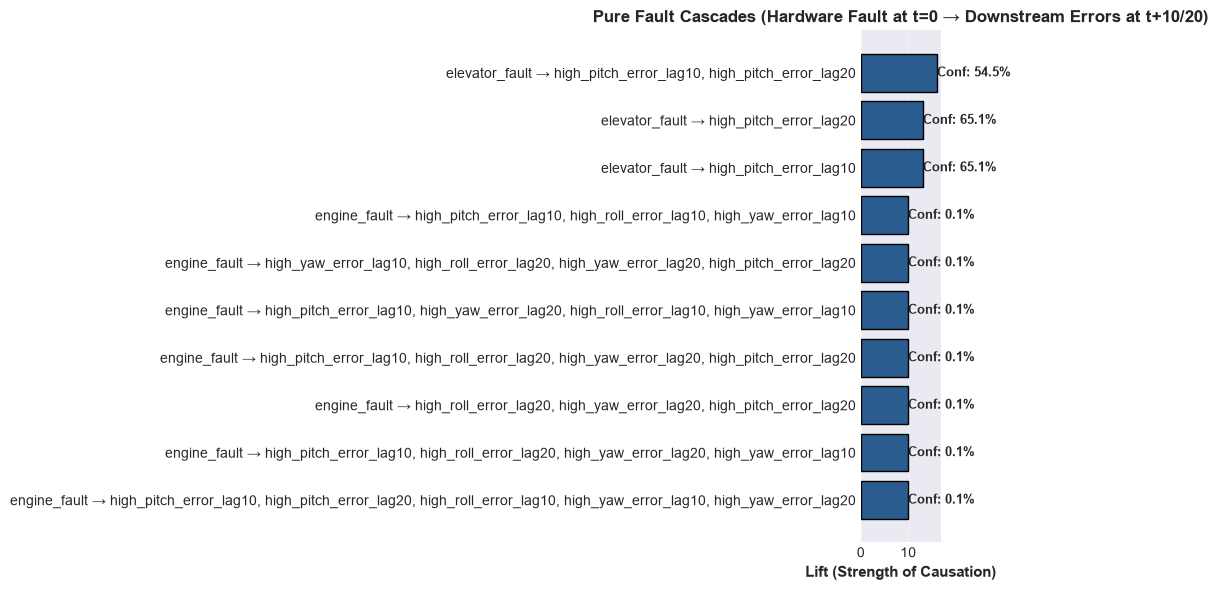

In [10]:
import matplotlib.pyplot as plt

if not pure_rules.empty:
    top_pure = pure_rules.head(10).iloc[::-1]
    
    plt.figure(figsize=(10, 6))
    bars = plt.barh(
        top_pure['antecedent_str'] + " → " + top_pure['consequent_str'], 
        top_pure['lift'], 
        color='#2b5c8f', 
        edgecolor='black'
    )
    
    plt.xlabel('Lift (Strength of Causation)', fontsize=11, fontweight='bold')
    plt.title('Pure Fault Cascades (Hardware Fault at t=0 → Downstream Errors at t+10/20)', fontsize=12, fontweight='bold')
    plt.grid(axis='x', linestyle='--', alpha=0.6)
    
    for bar, conf in zip(bars, top_pure['confidence']):
        plt.text(
            bar.get_width() + 0.05, 
            bar.get_y() + bar.get_height()/2, 
            f"Conf: {conf:.1%}", 
            va='center', fontsize=9, fontweight='bold'
        )
        
    plt.tight_layout()
    plt.show()
else:
    print("No pure rules found. Verify min_support threshold.")